In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("D:\SuperStoreOrders - SuperStoreOrders.csv")
print(df)

<>:1: SyntaxWarning: invalid escape sequence '\S'
<>:1: SyntaxWarning: invalid escape sequence '\S'
C:\Users\surji\AppData\Local\Temp\ipykernel_3612\3139410314.py:1: SyntaxWarning: invalid escape sequence '\S'
  df = pd.read_csv("D:\SuperStoreOrders - SuperStoreOrders.csv")


              order_id  order_date ship_date       ship_mode  \
0         AG-2011-2040    1/1/2011  6/1/2011  Standard Class   
1        IN-2011-47883    1/1/2011  8/1/2011  Standard Class   
2         HU-2011-1220    1/1/2011  5/1/2011    Second Class   
3      IT-2011-3647632    1/1/2011  5/1/2011    Second Class   
4        IN-2011-47883    1/1/2011  8/1/2011  Standard Class   
...                ...         ...       ...             ...   
51285   CA-2014-115427  31/12/2014  4/1/2015  Standard Class   
51286     MO-2014-2560  31/12/2014  5/1/2015  Standard Class   
51287   MX-2014-110527  31/12/2014  2/1/2015    Second Class   
51288   MX-2014-114783  31/12/2014  6/1/2015  Standard Class   
51289   CA-2014-156720  31/12/2014  4/1/2015  Standard Class   

          customer_name      segment             state        country  market  \
0       Toby Braunhardt     Consumer       Constantine        Algeria  Africa   
1           Joseph Holt     Consumer   New South Wales      Australia

In [7]:
print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())

          order_id order_date ship_date       ship_mode    customer_name  \
0     AG-2011-2040   1/1/2011  6/1/2011  Standard Class  Toby Braunhardt   
1    IN-2011-47883   1/1/2011  8/1/2011  Standard Class      Joseph Holt   
2     HU-2011-1220   1/1/2011  5/1/2011    Second Class    Annie Thurman   
3  IT-2011-3647632   1/1/2011  5/1/2011    Second Class     Eugene Moren   
4    IN-2011-47883   1/1/2011  8/1/2011  Standard Class      Joseph Holt   

       segment            state    country  market   region  ...  \
0     Consumer      Constantine    Algeria  Africa   Africa  ...   
1     Consumer  New South Wales  Australia    APAC  Oceania  ...   
2     Consumer         Budapest    Hungary    EMEA     EMEA  ...   
3  Home Office        Stockholm     Sweden      EU    North  ...   
4     Consumer  New South Wales  Australia    APAC  Oceania  ...   

          category sub_category                 product_name sales quantity  \
0  Office Supplies      Storage          Tenex Lockers,

In [8]:
print(df.isnull().sum())

order_id          0
order_date        0
ship_date         0
ship_mode         0
customer_name     0
segment           0
state             0
country           0
market            0
region            0
product_id        0
category          0
sub_category      0
product_name      0
sales             0
quantity          0
discount          0
profit            0
shipping_cost     0
order_priority    0
year              0
dtype: int64


In [9]:
print(df.duplicated().sum())

0


In [10]:
df.drop_duplicates(inplace=True)

In [11]:
print(df.dtypes)

order_id              str
order_date            str
ship_date             str
ship_mode             str
customer_name         str
segment               str
state                 str
country               str
market                str
region                str
product_id            str
category              str
sub_category          str
product_name          str
sales                 str
quantity            int64
discount          float64
profit            float64
shipping_cost     float64
order_priority        str
year                int64
dtype: object


In [12]:
df["order_date"] = pd.to_datetime(df["order_date"], dayfirst=True)

df["ship_date"] = pd.to_datetime(df["ship_date"],dayfirst=True)

# Convert sales into numeric format

df["sales"] = pd.to_numeric(df["sales"].astype(str).str.replace(",", "", regex=False).str.replace("$", "", regex=False))




In [13]:
print(df.dtypes)

order_id                     str
order_date        datetime64[us]
ship_date         datetime64[us]
ship_mode                    str
customer_name                str
segment                      str
state                        str
country                      str
market                       str
region                       str
product_id                   str
category                     str
sub_category                 str
product_name                 str
sales                      int64
quantity                   int64
discount                 float64
profit                   float64
shipping_cost            float64
order_priority               str
year                       int64
dtype: object


In [34]:
# Extract year, month, and day

df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_month_name"] = df["order_date"].dt.month_name()
df["order_day"] = df["order_date"].dt.day
df["order_day_name"] = df["order_date"].dt.day_name()

# shipping duration

df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days
print(df.shipping_days)


0        5
1        7
2        4
3        4
4        7
        ..
51285    4
51286    5
51287    2
51288    6
51289    4
Name: shipping_days, Length: 51290, dtype: int64


In [15]:
#  profit margin

df["profit_margin"] = np.where(df["sales"] != 0,(df["profit"] / df["sales"]) * 100,np.nan)
df.head()


,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year,shipping_days,profit_margin
0,AG-2011-2040,2011-01-01,2011-01-06,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,"Tenex Lockers, Blue",408,2,0.0,106.140,35.46,Medium,2011,5,26.014706
1,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,"Acme Trimmer, High Speed",120,3,0.1,36.036,9.72,Medium,2011,7,30.030000
2,HU-2011-1220,2011-01-01,2011-01-05,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,"Tenex Box, Single Width",66,4,0.0,29.640,8.17,High,2011,4,44.909091
3,IT-2011-3647632,2011-01-01,2011-01-05,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,"Enermax Note Cards, Premium",45,3,0.5,-26.055,4.82,High,2011,4,-57.900000
4,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,"Eldon Light Bulb, Duo Pack",114,5,0.1,37.770,4.70,Medium,2011,7,33.131579


In [16]:
# Total performance

total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_name"].nunique()
total_quantity = df["quantity"].sum()
average_order_sales = df.groupby("order_id")["sales"].sum().mean()
average_profit_margin = (total_profit / total_sales) * 100

print("Total Sales:",total_sales)
print("Total Profit:",total_profit)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)
print("Average Order Value:", average_order_sales)
print("Overall Profit Margin:",average_profit_margin, "%")



Total Sales: 12642905
Total Profit: 1469034.82128
Total Orders: 25035
Total Customers: 795
Total Quantity Sold: 178312
Average Order Value: 505.0091871380068
Overall Profit Margin: 11.619440478908922 %


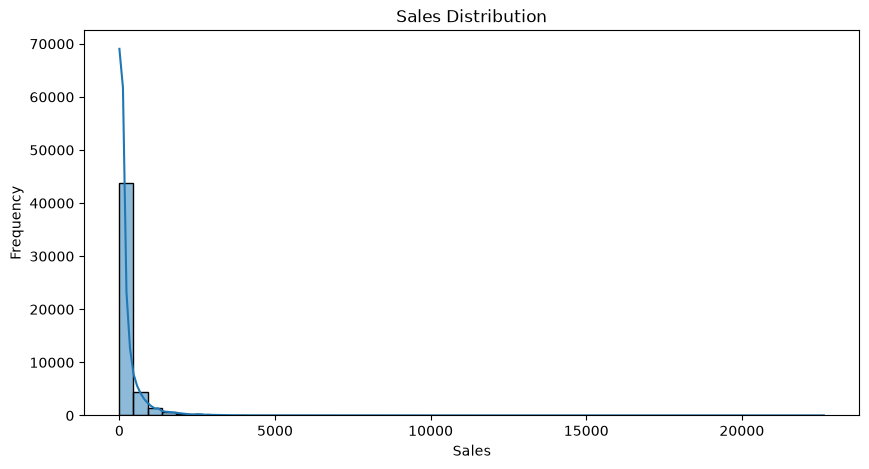

In [17]:
# Sales distribution

plt.figure(figsize=(10, 5))
sns.histplot(df["sales"], bins=50, kde=True)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()


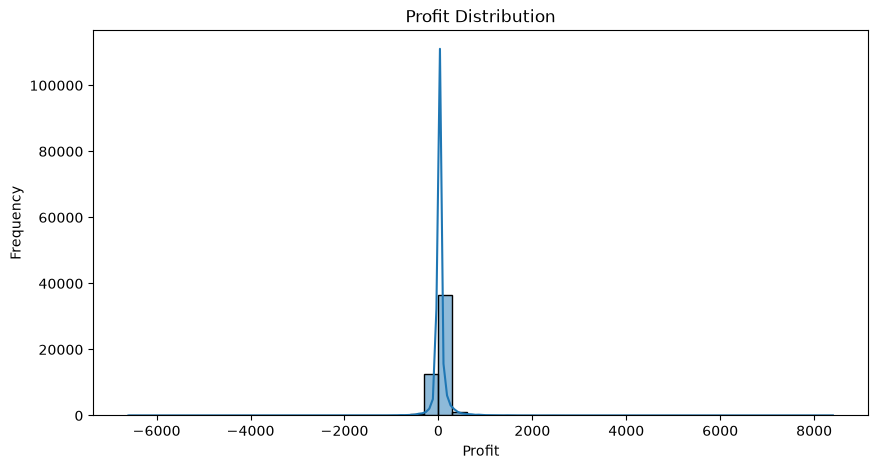

In [18]:
# Profit distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["profit"], bins=50, kde=True)
plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()


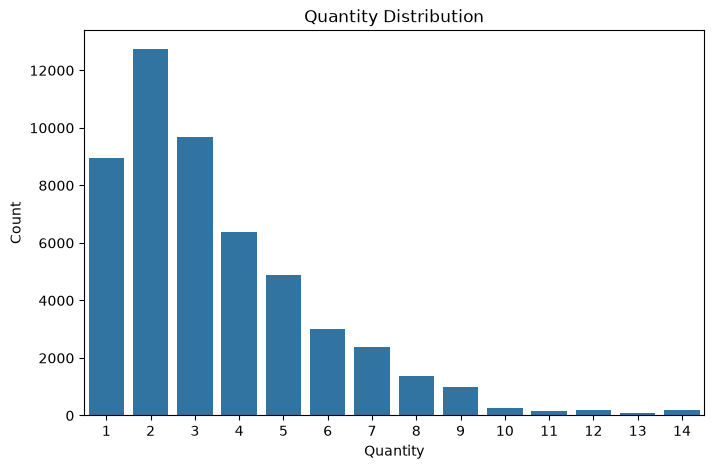

In [19]:
# Quantity distribution

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quantity")
plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Count")
plt.show()



Orders by Category:
category
Office Supplies    31273
Technology         10141
Furniture           9876
Name: count, dtype: int64


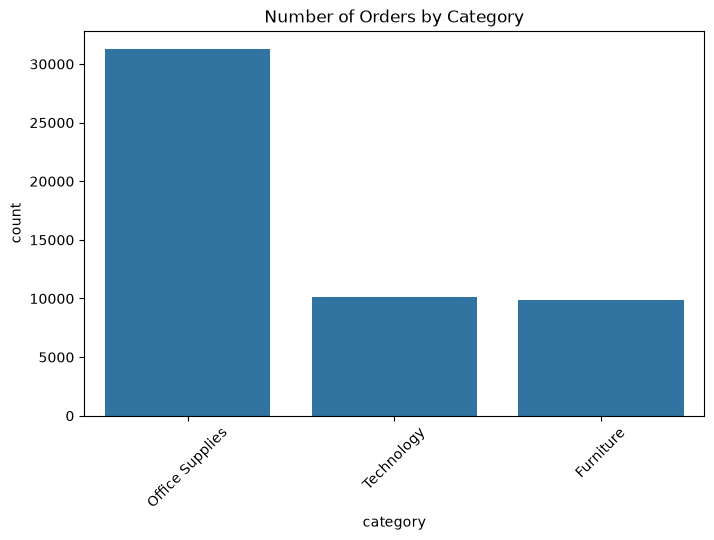

In [20]:
# Orders by category (category analysis)
print("\nOrders by Category:")
print(df["category"].value_counts())
plt.figure(figsize=(8, 5))
sns.countplot(data=df,x="category",order=df["category"].value_counts().index)
plt.title("Number of Orders by Category")
plt.xticks(rotation=45)
plt.show()



Orders by Region:
region
Central           11117
South              6645
EMEA               5029
North              4785
Africa             4587
Oceania            3487
West               3203
Southeast Asia     3129
East               2848
North Asia         2338
Central Asia       2048
Caribbean          1690
Canada              384
Name: count, dtype: int64


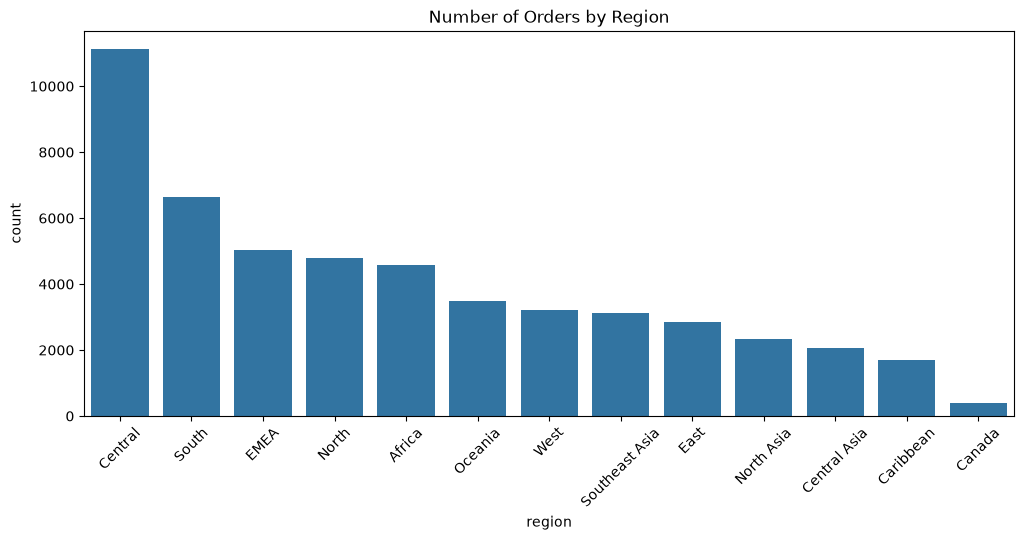

In [21]:
# Orders by region
print("\nOrders by Region:")
print(df["region"].value_counts())
plt.figure(figsize=(12, 5))
sns.countplot(data=df,x="region",order=df["region"].value_counts().index)
plt.title("Number of Orders by Region")
plt.xticks(rotation=45)
plt.show()




Orders by Segment:
segment
Consumer       26518
Corporate      15429
Home Office     9343
Name: count, dtype: int64


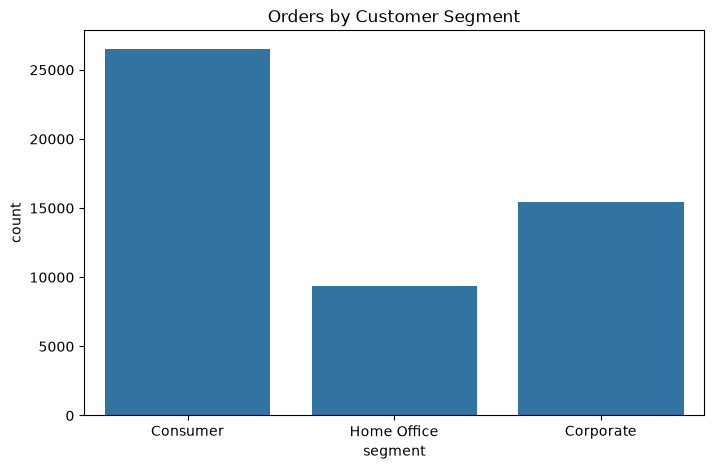

In [22]:
# Orders by customer segment

print("\nOrders by Segment:")
print(df["segment"].value_counts())
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="segment")
plt.title("Orders by Customer Segment")
plt.show()


In [23]:
# Sales and profit by category

category_analysis = df.groupby("category")[["sales", "profit", "quantity"]].sum().sort_values("sales", ascending=False)
print("\nSales and Profit by Category:")
print(category_analysis)



Sales and Profit by Category:
                   sales        profit  quantity
category                                        
Technology       4744691  663778.73318     35176
Furniture        4110884  286782.25380     34954
Office Supplies  3787330  518473.83430    108182


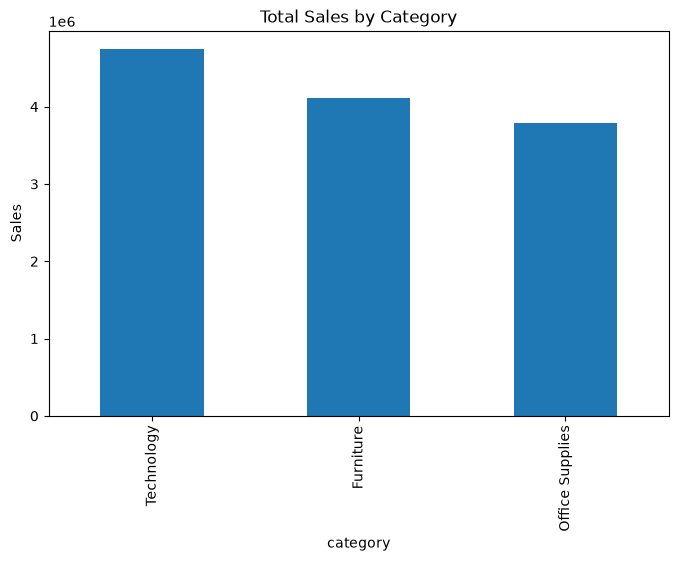

In [24]:
category_analysis["sales"].plot( kind="bar",figsize=(8, 5),title="Total Sales by Category")
plt.ylabel("Sales")
plt.show()


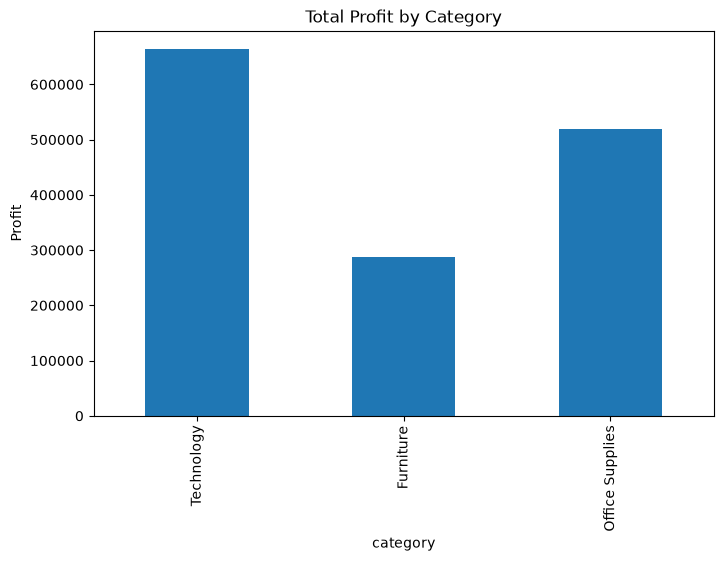

In [25]:
# Profit by category

category_analysis["profit"].plot(kind="bar",figsize=(8, 5),title="Total Profit by Category")
plt.ylabel("Profit")
plt.show()



Sales and Profit by Sub-Category:
                sales        profit
sub_category                       
Copiers       1509439  258567.54818
Phones        1706874  216717.00580
Bookcases     1466559  161924.41950
Chairs        1501682  141973.79750
Appliances    1011081  141680.58940
Accessories    749307  129626.30620
Storage       1127124  108461.48980
Binders        461952   72449.84600
Paper          244307   59207.68270
Machines       779071   58867.87300
Art            372163   57953.91090
Furnishings    385609   46967.42550
Envelopes      170926   29601.11630
Supplies       243090   22583.26310
Labels          73433   15010.51200
Fasteners       83254   11525.42410
Tables         757034  -64083.38870


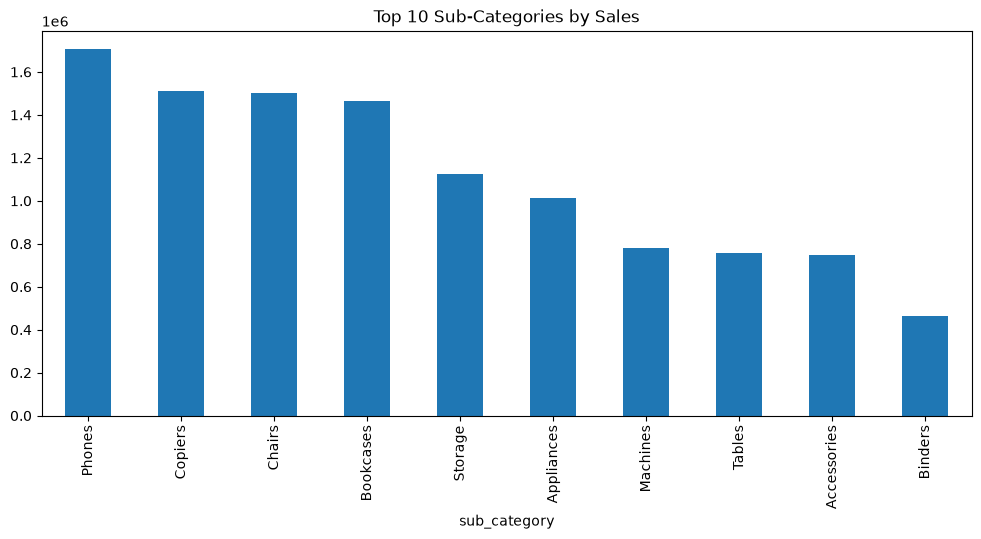

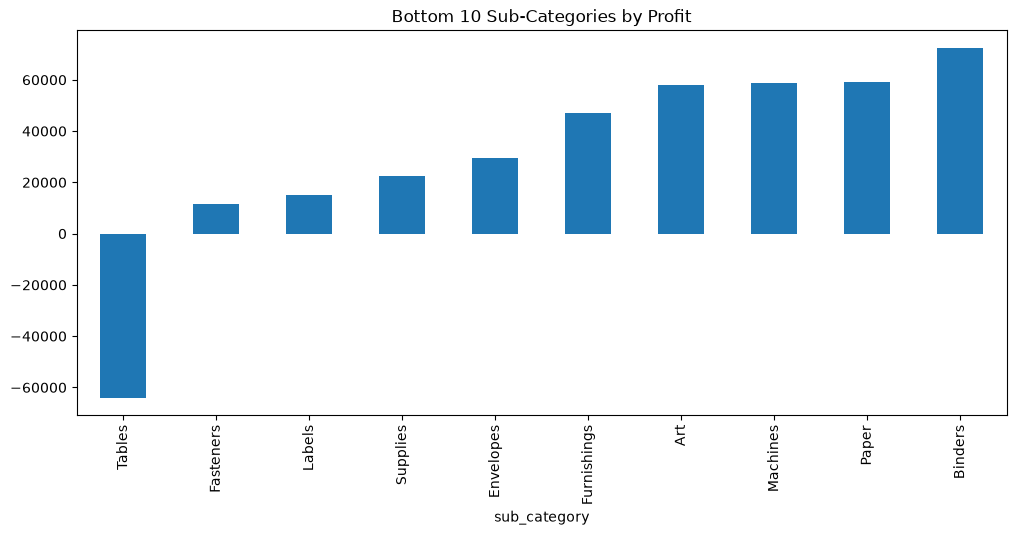

In [26]:
# Sales and profit by sub-category

subcategory_analysis = df.groupby("sub_category")[["sales", "profit"]].sum().sort_values("profit", ascending=False)
print("\nSales and Profit by Sub-Category:")
print(subcategory_analysis)

top_subcategories = subcategory_analysis.sort_values("sales",ascending=False).head(10)

top_subcategories["sales"].plot(kind="bar",figsize=(12, 5),title="Top 10 Sub-Categories by Sales")
plt.show()


bottom_subcategories = subcategory_analysis.sort_values("profit",ascending=True).head(10)
bottom_subcategories["profit"].plot(kind="bar",figsize=(12, 5),title="Bottom 10 Sub-Categories by Profit")
plt.show()



Regional Sales and Profit:
                  sales        profit
region                               
Central         2822399  311403.98164
South           1600960  140355.76618
North           1248192  194597.95252
Oceania         1100207  121666.64200
Southeast Asia   884438   17852.32900
North Asia       848349  165578.42100
EMEA             806184   43897.97100
Africa           783776   88871.63100
Central Asia     752839  132480.18700
West             725514  108418.44890
East             678834   91522.78000
Caribbean        324281   34571.32104
Canada            66932   17817.39000


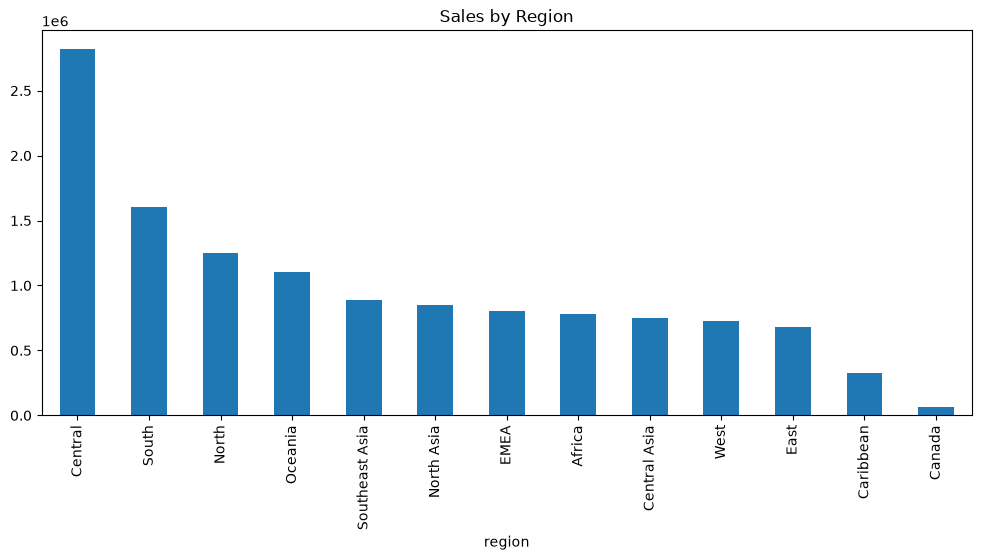

In [27]:
# Region wise analysis

region_analysis = df.groupby("region")[["sales", "profit"]].sum().sort_values("sales", ascending=False)
print("\nRegional Sales and Profit:")
print(region_analysis)

# Sales by region

region_analysis["sales"].plot(kind="bar",figsize=(12, 5),title="Sales by Region")
plt.show()


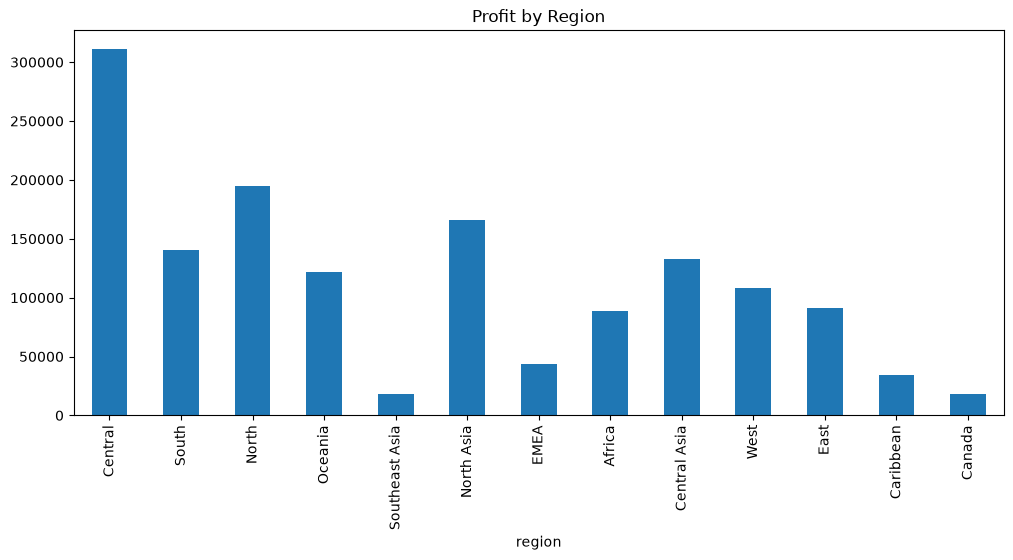

In [28]:
# Profit by region

region_analysis["profit"].plot(kind="bar",figsize=(12, 5),title="Profit by Region")
plt.show()



Yearly Sales:
order_year
2011    2259511
2012    2677493
2013    3405860
2014    4300041
Name: sales, dtype: int64


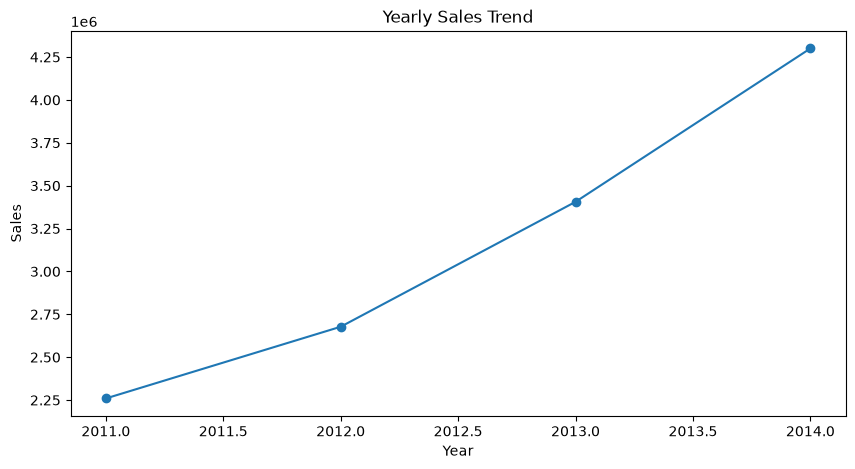


Monthly Sales:
order_date
2011-01-01     98902
2011-02-01     91152
2011-03-01    145726
2011-04-01    116927
2011-05-01    146762
2011-06-01    215214
2011-07-01    115518
2011-08-01    207570
2011-09-01    290230
2011-10-01    199070
2011-11-01    298499
2011-12-01    333941
2012-01-01    135775
2012-02-01    100521
2012-03-01    163092
2012-04-01    161060
2012-05-01    208370
2012-06-01    256181
2012-07-01    145247
2012-08-01    303158
2012-09-01    289390
2012-10-01    252942
2012-11-01    323512
2012-12-01    338245
2013-01-01    199197
2013-02-01    167247
2013-03-01    198591
2013-04-01    177835
2013-05-01    260525
2013-06-01    396513
2013-07-01    229940
2013-08-01    326491
2013-09-01    376626
2013-10-01    293423
2013-11-01    373996
2013-12-01    405476
2014-01-01    241267
2014-02-01    184848
2014-03-01    263110
2014-04-01    242781
2014-05-01    288404
2014-06-01    401843
2014-07-01    258718
2014-08-01    456633
2014-09-01    481186
2014-10-01    422785
2014-11

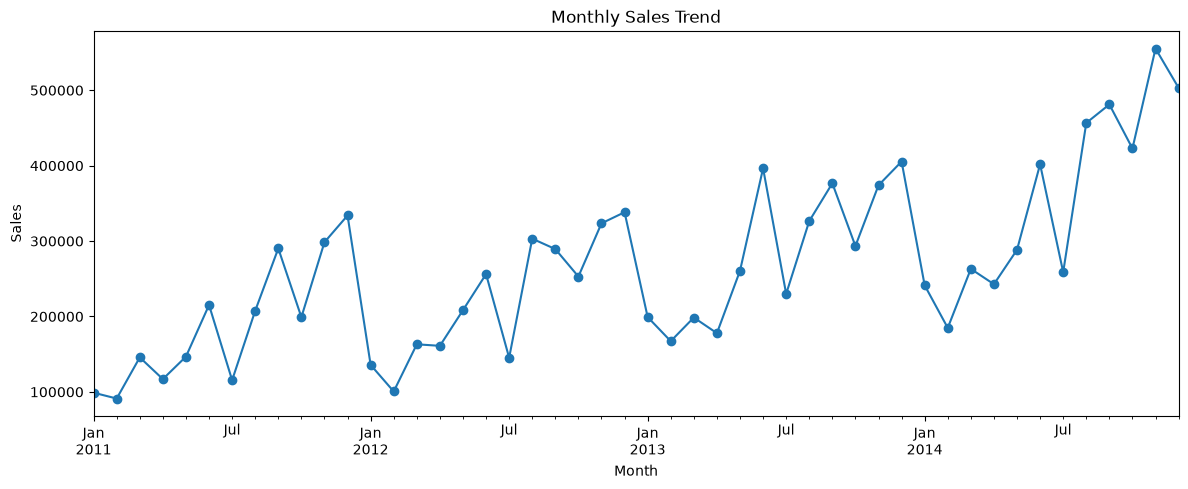

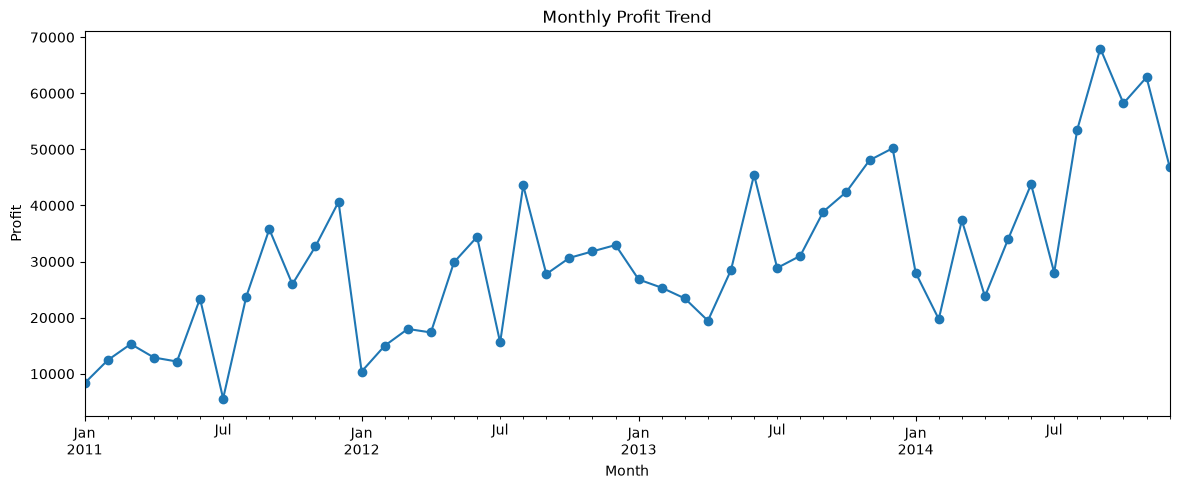

In [35]:
# Yearly sales

yearly_sales = df.groupby("order_year")["sales"].sum()
print("\nYearly Sales:")
print(yearly_sales)
yearly_sales.plot(kind="line",marker="o",figsize=(10, 5),title="Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.show()

# Monthly sales

monthly_sales = df.groupby(df["order_date"].dt.to_period("M"))["sales"].sum()
monthly_sales.index = monthly_sales.index.to_timestamp()
print("\nMonthly Sales:")
print(monthly_sales)
monthly_sales.plot(kind="line",marker="o",figsize=(14, 5),title="Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()

# Monthly profit

monthly_profit = df.groupby(df["order_date"].dt.to_period("M"))["profit"].sum()
monthly_profit.index = monthly_profit.index.to_timestamp()
monthly_profit.plot(kind="line",marker="o",figsize=(14, 5),title="Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.show()




Shipping Mode Analysis:
                     sales     profit  shipping_cost  shipping_days
ship_mode                                                          
First Class     243.979614  27.728804      41.053065       2.181746
Same Day        247.020363  28.201802      42.937453       0.037394
Second Class    248.884179  28.534393      30.469747       3.230187
Standard Class  246.267717  28.938945      19.971755       4.998018


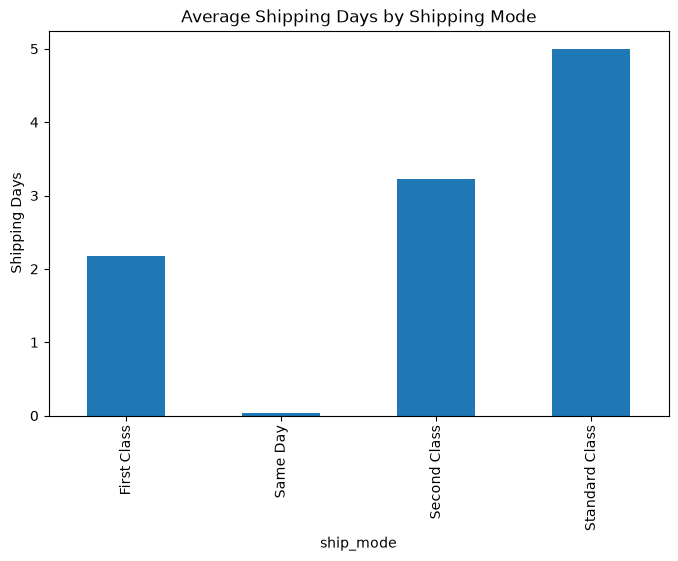

In [37]:
# Shipping mode analysis

shipping_analysis = df.groupby("ship_mode")[["sales", "profit", "shipping_cost", "shipping_days"]].mean()
print("\nShipping Mode Analysis:")
print(shipping_analysis)

# Average shipping duration by shipping mode

shipping_analysis["shipping_days"].plot(kind="bar",figsize=(8, 5),title="Average Shipping Days by Shipping Mode")
plt.ylabel("Shipping Days")
plt.show()



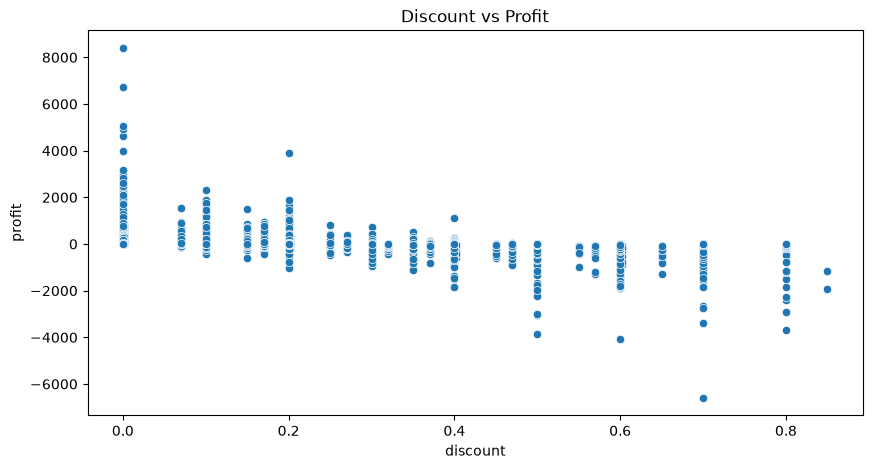


Average Profit by Discount:
discount
0.000      61.039514
0.002     125.762649
0.070     140.990022
0.100      64.071216
0.150      50.602409
0.170      38.317107
0.200      23.552594
0.202     -14.518847
0.250       4.043371
0.270      -4.317213
0.300     -57.899557
0.320     -88.560656
0.350    -116.144693
0.370     -78.462191
0.400     -45.246603
0.402    -109.908138
0.450     -41.610973
0.470     -42.982420
0.500     -97.140158
0.550    -315.067200
0.570    -526.129000
0.600     -81.732147
0.602    -213.279085
0.650    -365.997971
0.700    -104.339576
0.800    -122.203244
0.850   -1534.329000
Name: profit, dtype: float64


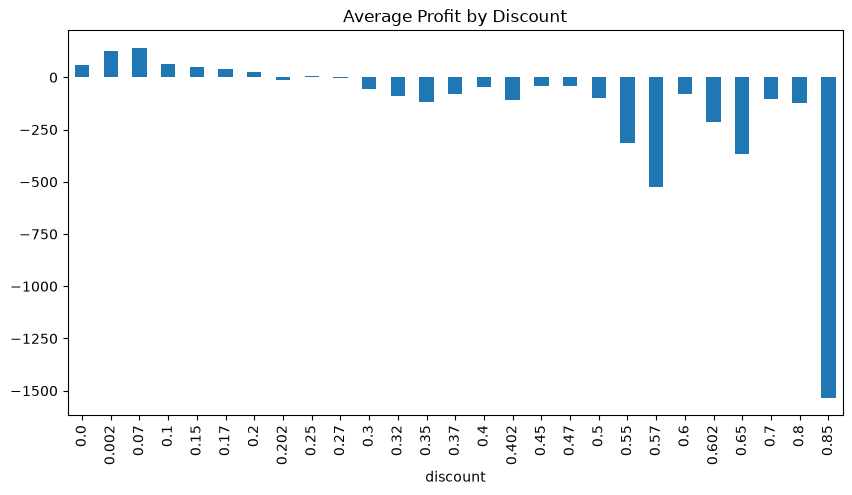

In [38]:
# Discount and profit relationship

plt.figure(figsize=(10, 5))

sns.scatterplot(data=df,x="discount",y="profit")
plt.title("Discount vs Profit")
plt.show()

# Average profit by discount

discount_analysis = df.groupby("discount")["profit"].mean()
print("\nAverage Profit by Discount:")
print(discount_analysis)
discount_analysis.plot(kind="bar",figsize=(10, 5),title="Average Profit by Discount")
plt.show()



Correlation Matrix:
                  sales  quantity  discount    profit  shipping_cost  \
sales          1.000000  0.313580 -0.086728  0.485944       0.768075   
quantity       0.313580  1.000000 -0.019875  0.104743       0.272649   
discount      -0.086728 -0.019875  1.000000 -0.316375      -0.079056   
profit         0.485944  0.104743 -0.316375  1.000000       0.357033   
shipping_cost  0.768075  0.272649 -0.079056  0.357033       1.000000   
year          -0.002902 -0.005049 -0.005894  0.002661      -0.003136   
shipping_days -0.004661  0.004347 -0.001507  0.001543      -0.142823   
profit_margin  0.074710  0.050487 -0.846445  0.357199       0.067945   
order_year    -0.002902 -0.005049 -0.005894  0.002661      -0.003136   
order_month    0.001813  0.020611  0.000027 -0.000156       0.004929   
order_day      0.002320  0.004509 -0.006320 -0.002629       0.005266   

                   year  shipping_days  profit_margin  order_year  \
sales         -0.002902      -0.004661       

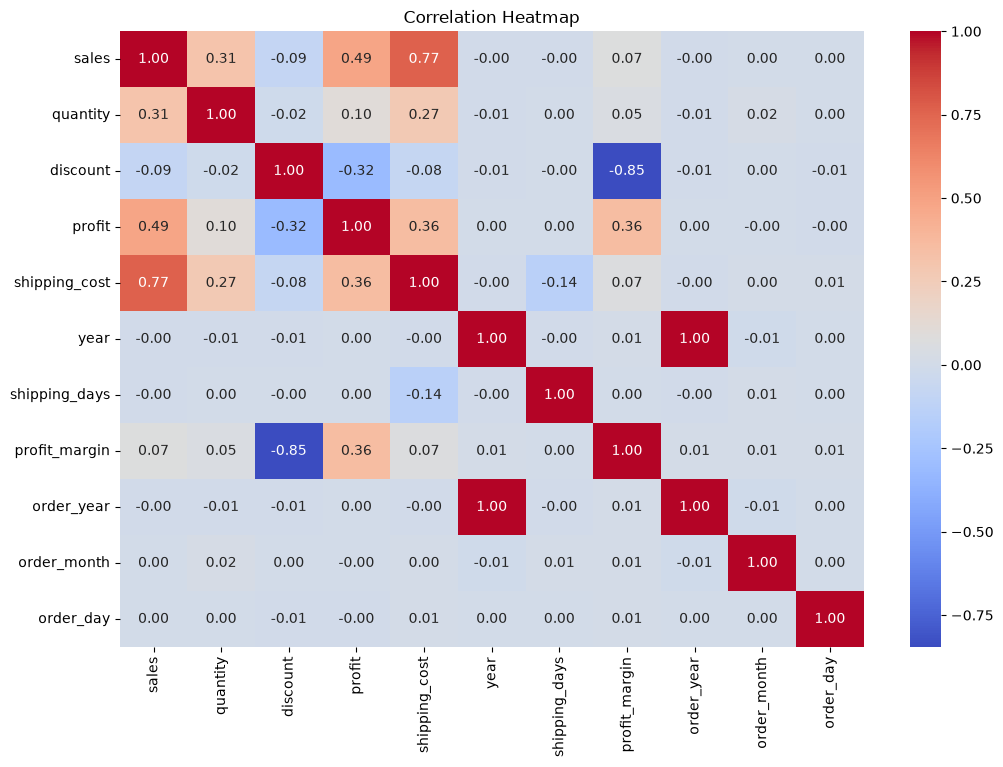

In [39]:
# Correlation

numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()
print("\nCorrelation Matrix:")
print(correlation)
plt.figure(figsize=(12, 8))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


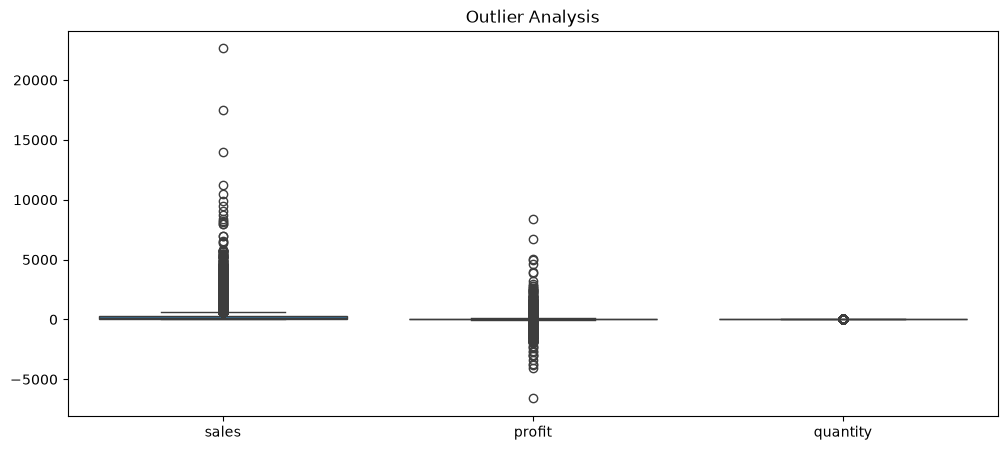

In [40]:
# Outlier Analysis

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[["sales", "profit", "quantity"]])
plt.title("Outlier Analysis")
plt.show()
